# Introduction to domain adaptation with `skada`

Authors: [Pedro L. C. Rodrigues](https://plcrodrigues.github.io) and [Thomas Moreau](https://tommoral.github.io)

Domain adaptation is a subfield of machine learning that tackles a fundamental challenge: models trained on one data distribution often fail when deployed in a different but related setting. This performance drop is caused by a **dataset shift** between the labelled *source* domain used for training and the unlabelled *target* domain encountered at inference time. 

Such shifts are ubiquitous in practice — a computer vision model trained on synthetic images may struggle on real photographs, a medical classifier trained on data from one hospital may underperform at another due to differences in equipment or patient demographics, and a speech recognition system trained in a quiet studio may degrade in noisy environments. Domain adaptation methods aim to bridge this gap, leveraging the unlabelled target data to adapt the model without requiring expensive target annotations. 

Formally, we denote by $X$ the input features and $y$ the associated labels; the source and target domains are respectively characterised by joint distributions $P^s(X, y)$ and $P^t(X, y)$, which are assumed to differ. The distributional mismatch, broadly called *dataset shift*, can take four forms:

- **Covariate shift**: the marginal input distribution changes ($P^s(X) \neq P^t(X)$) while the class-conditional relationship remains intact ($P^s(y|X) = P^t(y|X)$).
- **Target shift**: the label marginal changes ($P^s(y) \neq P^t(y)$) while the class-conditional feature distribution is preserved ($P^s(X|y) = P^t(X|y)$).
- **Conditional shift**: the class-conditional distributions themselves differ across domains ($P^s(y|X) \neq P^t(y|X)$ or $P^s(X|y) \neq P^t(X|y)$).
- **Subspace shift**: although $P^s(X) \neq P^t(X)$, there exists a projection $W$ such that $P^s(WX) = P^t(WX)$, meaning the shift can be corrected by moving to a lower-dimensional subspace.

The [`skada`](https://scikit-adaptation.github.io/) package provides a unified, scikit-learn-compatible implementation of a wide range of domain adaptation methods, covering shallow approaches such as sample reweighting, optimal transport, and subspace alignment, as well as deep learning methods including DANN and DeepJDOT.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

%matplotlib inline

In [2]:
!pip install skada

Let's start by creating a simulated dataset using `skada`.

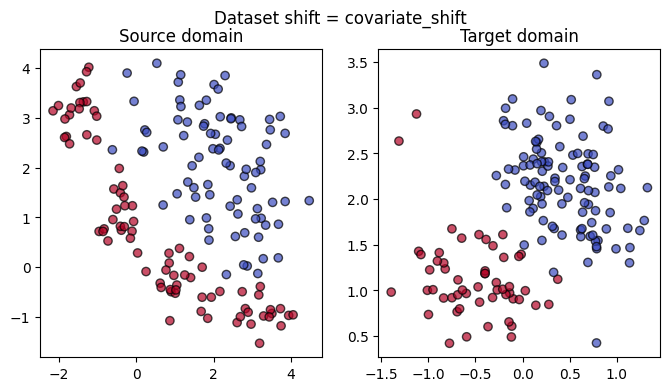

In [3]:
from skada import source_target_split
from skada.datasets import make_shifted_datasets

import matplotlib.pyplot as plt

random_state = 42

shift = 'covariate_shift'

X, y, sample_domain = make_shifted_datasets(
    n_samples_source=20,
    n_samples_target=20,
    shift=shift,
    noise=0.3,
    label="binary",
    random_state=random_state,
)

X_source, X_target, y_source, y_target = source_target_split(
    X, y, sample_domain=sample_domain)

fig, ax = plt.subplots(figsize=(8, 4), ncols=2)
fig.suptitle(f'Dataset shift = {shift}')
ax[0].scatter(X_source[:, 0], X_source[:, 1], c=y_source, cmap="coolwarm", edgecolor="k", alpha=0.7)
ax[0].set_title("Source domain")
ax[1].scatter(X_target[:, 0], X_target[:, 1], c=y_target, cmap="coolwarm", edgecolor="k", alpha=0.7)
ax[1].set_title("Target domain")
plt.show()


<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
         <li>How would you proceed to determine the type of shift of a given pair of source-target datasets? (suppose that you know labels Y on both domains)</li>
         <li>Apply your proposal to the datasets stored in dataset_exercise.pkl and determine which kind of shift we have.
     </ul>
</div>

With full access to $(X_t, y_t)$ you can directly estimate and compare all the relevant distributions:

- **Covariate shift**: compare $P^s(X)$ vs $P^t(X)$ with a two-sample test (MMD, Wasserstein, per-feature KS). Then verify that $P^s(y|X) \approx P^t(y|X)$ by training a classifier on source and checking that its accuracy on target remains comparable.

- **Target shift**: compare the empirical label frequencies $P^s(y)$ vs $P^t(y)$ directly via a histogram comparison or chi-squared test. Then verify $P^s(X|y) \approx P^t(X|y)$ by comparing class-conditional feature distributions class by class.

- **Conditional shift**: train a classifier on source and one on target, and compare their outputs on the same inputs. If $P^s(y|X)$ and $P^t(y|X)$ differ noticeably while $P^s(y) \approx P^t(y)$, you have conditional shift.

- **Subspace shift**: run PCA or CCA on the combined data and check whether source and target align in a low-dimensional projection even if they differ globally. If the shift is concentrated along only a few principal components, subspace shift is a good candidate.

Comparing $P^s(X)$ Vs $P^t(X)$

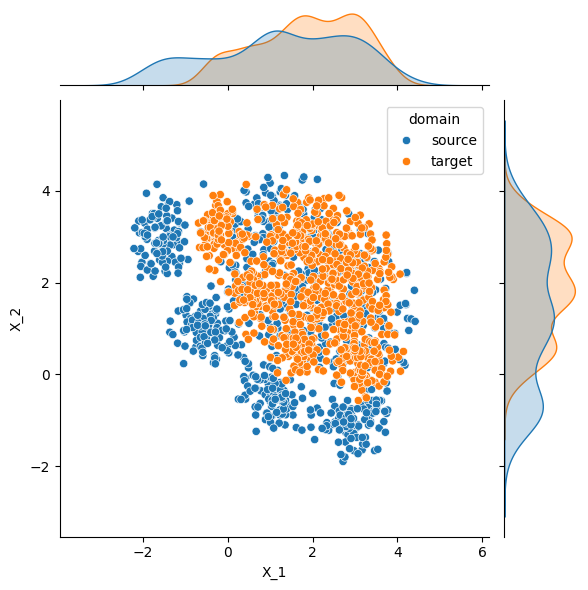

In [55]:
import seaborn as sns
import pandas as pd
import joblib

data = joblib.load("dataset_exercise.pkl")
X = data["X"]
y = data["y"]
sample_domain = data["sample_domain"]

X_source, X_target, y_source, y_target = source_target_split(
    X, y, sample_domain=sample_domain)

data_source = pd.DataFrame(X_source, columns=['X_1', 'X_2'])
data_source['domain'] = len(data_source)*['source']
data_target = pd.DataFrame(X_target, columns=['X_1', 'X_2'])
data_target['domain'] = len(data_target)*['target']
data = pd.concat([data_source, data_target])
# sns.pairplot(data_source)
sns.jointplot(data=data, x='X_1', y='X_2', hue='domain')
plt.show()


Checking the classifier boundaries for $P^s(y|X)$ Vs $P^t(y|X)$

Source domain accuracy: 0.9950
Target domain accuracy: 0.5288


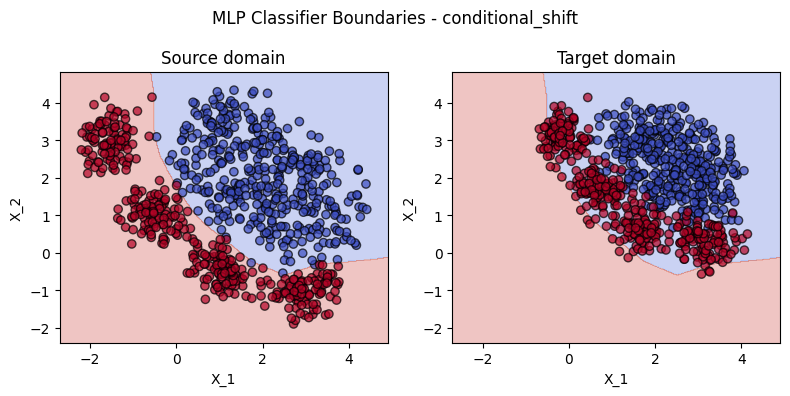

In [51]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
import numpy as np

import matplotlib.pyplot as plt

# Train MLP on source data
scaler = StandardScaler()
X_source_scaled = scaler.fit_transform(X_source)

mlp = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=random_state)
mlp.fit(X_source_scaled, y_source)

# Create mesh for decision boundary
h = 0.02
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

Z = mlp.predict(scaler.transform(np.c_[xx.ravel(), yy.ravel()]))
Z = Z.reshape(xx.shape)

# Plot classifier boundaries
fig, ax = plt.subplots(figsize=(8, 4), ncols=2)
fig.suptitle(f'MLP Classifier Boundaries - {shift}')

# Source domain
ax[0].contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
ax[0].scatter(X_source[:, 0], X_source[:, 1], c=y_source, cmap="coolwarm", edgecolor="k", alpha=0.7)
ax[0].set_title("Source domain")
ax[0].set_xlabel("X_1")
ax[0].set_ylabel("X_2")

# Target domain
ax[1].contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
ax[1].scatter(X_target[:, 0], X_target[:, 1], c=y_target, cmap="coolwarm", edgecolor="k", alpha=0.7)
ax[1].set_title("Target domain")
ax[1].set_xlabel("X_1")
ax[1].set_ylabel("X_2")

source_score = mlp.score(X_source_scaled, y_source)
target_score = mlp.score(scaler.transform(X_target), y_target)
print(f"Source domain accuracy: {source_score:.4f}")
print(f"Target domain accuracy: {target_score:.4f}")

plt.tight_layout()
plt.show()

In most practical cases, however, **target labels are unavailable** — annotating target data is precisely what we want to avoid. This setting is known as *unsupervised domain adaptation*, and it is the one we focus on throughout this notebook. 

As a consequence, diagnosing which type of dataset shift is at play becomes significantly harder, since we can no longer directly compare class-conditional distributions or label marginals on the target side.